# Lab 2: Curvature, conditioning, and the three remedies

**Optimization for AI (020OAIES5), ESIB.** This lab accompanies chapter 3
(Geometry, Scaling, and Conditioning). The chapter analyzes a quadratic bowl,
where the Hessian is one constant matrix and every statement is exact. This
lab repeats the analysis on a convex problem that is not quadratic, a logistic
regression, where the Hessian changes from point to point. The same numbers
govern the run (eigenvalues, contraction factors, the threshold
$2/\lambda_{\max}$, the condition number $\kappa$), but each is a local
statement whose accuracy you will measure. The lab is take-home and
self-checking: every exercise ends with a check cell that compares your
results against reference values computed to full precision. Work top to
bottom; a check cell only passes once the exercise above it is complete.

**Requirements.** Python 3 with NumPy and Matplotlib. PyTorch is needed only
for the optional final exercise.

**What to submit.** The executed notebook, with every check cell reporting
`all checks passed` and the two written answers filled in.

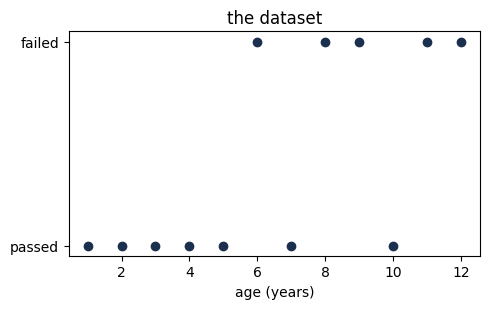

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Course palette
NAVY, TEAL, RUST, GREEN, GOLD = "#1B2F4E", "#157A8B", "#C0562F", "#2E7D32", "#C8A24B"

# Twelve pumps in a plant: age in years, and whether the pump failed its
# annual inspection (+1 failed, -1 passed). Old pumps fail more often, with
# exceptions on both sides, so no threshold on the age separates the classes.
x = np.arange(1, 13, dtype=float)
y = np.array([-1, -1, -1, -1, -1, +1, -1, +1, +1, -1, +1, +1], dtype=float)
N = len(x)

plt.figure(figsize=(5, 3.2))
plt.scatter(x, (y + 1) / 2, color=NAVY)
plt.yticks([0, 1], ["passed", "failed"])
plt.xlabel("age (years)")
plt.title("the dataset")
plt.tight_layout(); plt.show()

## Part A: the problem

### Exercise 1: the loss, the gradient, and the Hessian

The model gives the probability of failure at age $x$ as
$p(x) = \sigma(wx + b)$, with $\sigma(z) = 1/(1 + e^{-z})$ and parameters
$\theta = (w, b)$. In the notation of chapter 2, the margin of example $i$
is $z_i = y_i (w x_i + b)$, its loss is $g(z_i) = \log(1 + e^{-z_i})$, and
the training loss is the average

$$\mathcal{L}(w, b) = \frac{1}{N} \sum_{i=1}^{N} \log\big(1 + e^{-y_i (w x_i + b)}\big) .$$

Chapter 2 proved this loss convex from $g'(z) = \sigma(z) - 1$ and
$g''(z) = \sigma(z)\big(1 - \sigma(z)\big) > 0$. The chain rule through the
affine margin gives, writing $\tilde{x}_i = (x_i, 1)$ and using $y_i^2 = 1$,

$$\nabla \mathcal{L} = \frac{1}{N} \sum_i \big(\sigma(z_i) - 1\big)\, y_i\, \tilde{x}_i,
\qquad
H(w, b) = \frac{1}{N} \sum_i \sigma(z_i)\big(1 - \sigma(z_i)\big)\, \tilde{x}_i \tilde{x}_i^\top .$$

Implement `loss`, `grad`, and `hessian`. Each takes the feature vector as an
optional last argument `xs` (default `x`) so that exercise 7 can swap it for
a rescaled one. Use `np.logaddexp(0, -z)` for $\log(1 + e^{-z})$: it does not
overflow. Reference values: $\mathcal{L}(0, 0) = \ln 2 = 0.6931$,
$\mathcal{L}(0.5, -3) = 0.4692$, $\nabla \mathcal{L}(0, 0) = (-0.5833,\ 0.0833)$,
and $H(0, 0) = \begin{pmatrix} 13.5417 & 1.625 \\ 1.625 & 0.25 \end{pmatrix}$.
At the origin every $\sigma(z_i)$ equals $1/2$, so $H(0, 0)$ is one quarter of
the mean of $\tilde{x}_i \tilde{x}_i^\top$; since $\sigma(1 - \sigma) \le 1/4$
everywhere, no other point has larger curvature in any direction.

In [4]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def loss(w, b, xs=x):
    """Mean logistic loss of the parameters (w, b) on the dataset."""
    z = y*(w*xs + b)
    return np.mean(np.logaddexp(0, -z))
    

def grad(w, b, xs=x):
    """Gradient of the loss at (w, b), returned as a length-2 array."""
    z = y*(w*xs + b)
    weights = (sigmoid(z) - 1)*y
    
    dL_dw = np.mean(weights * xs)
    dL_db = np.mean(weights)
    return np.array([dL_dw, dL_db])

def hessian(w, b, xs=x):
    """Hessian of the loss at (w, b), a 2 x 2 array."""
    z = y * (w * xs + b)
    p = sigmoid(z)
    weights = p * (1 - p)
    
    H_ww = np.mean(weights * xs**2)
    H_wb = np.mean(weights * xs)
    H_bb = np.mean(weights)

    return np.array([
        [H_ww, H_wb],
        [H_wb, H_bb]
    ])


In [5]:
# Check cell for exercise 1. Do not modify.
assert np.isclose(loss(0.0, 0.0), np.log(2), atol=1e-6), "loss(0, 0) should be ln 2 = 0.6931"
assert np.isclose(loss(0.5, -3.0), 0.469239, atol=1e-5), "loss(0.5, -3) should be 0.4692"
assert np.allclose(grad(0.0, 0.0), [-0.583333, 0.083333], atol=1e-5), "grad(0, 0) should be (-0.5833, 0.0833)"

def fd_grad(w, b, h=1e-6):
    return np.array([(loss(w + h, b) - loss(w - h, b)) / (2 * h),
                     (loss(w, b + h) - loss(w, b - h)) / (2 * h)])

def fd_hessian(w, b, h=1e-5):
    return np.column_stack([(grad(w + h, b) - grad(w - h, b)) / (2 * h),
                            (grad(w, b + h) - grad(w, b - h)) / (2 * h)])

assert np.allclose(grad(0.5, -3.0), fd_grad(0.5, -3.0), atol=1e-5), \
    "the analytic gradient disagrees with the finite difference"
assert np.allclose(hessian(0.5, -3.0), fd_hessian(0.5, -3.0), atol=1e-5), \
    "the analytic Hessian disagrees with the finite difference of the gradient"
H0 = hessian(0.0, 0.0)
assert np.allclose(H0, [[13.541667, 1.625], [1.625, 0.25]], atol=1e-5), \
    "H(0, 0) should be [[13.5417, 1.625], [1.625, 0.25]]"
assert np.allclose(H0, H0.T), "the Hessian must be symmetric"
H_far = hessian(0.5845, -4.4216)
print("eigenvalues of H at (0, 0):        ", np.round(np.linalg.eigvalsh(H0)[::-1], 4))
print("eigenvalues of H at (0.58, -4.42): ", np.round(np.linalg.eigvalsh(H_far)[::-1], 4))
assert H_far[0, 0] < H0[0, 0], "the curvature must be smaller away from the origin"
print("Exercise 1: all checks passed")

eigenvalues of H at (0, 0):         [13.7375  0.0542]
eigenvalues of H at (0.58, -4.42):  [8.0945 0.0136]
Exercise 1: all checks passed


## Part B: the eigen-analysis

### Exercise 2: the eigen-axes at the minimizer

The minimizer is $\theta^* = (0.5845,\ -4.4216)$ with $\mathcal{L}^* = 0.4174$;
exercise 5 computes it, and until then it is given. Around $\theta^*$ the
second-order Taylor expansion

$$\mathcal{L}(\theta) \approx \mathcal{L}^* + \tfrac{1}{2}\, \mathbf{e}^\top H^* \mathbf{e},
\qquad \mathbf{e} = \theta - \theta^*, \quad H^* = H(\theta^*),$$

is the bowl of the chapter, but only approximately and only nearby: the
third derivatives no longer vanish. Its level sets are ellipses whose axes
are the eigenvectors of $H^*$ and whose semi-axes at height
$\Delta\mathcal{L}$ are $\sqrt{2\Delta\mathcal{L}/\lambda}$.

Implement `eig_axes(H)`, which returns `(lam_flat, lam_steep, q_flat,
q_steep)` with unit eigenvectors whose first component is nonnegative
(`np.linalg.eigh` returns the eigenvalues in ascending order and the
eigenvectors as columns), and `semi_axes(lam_flat, lam_steep, delta_L)`.
Reference values: $\lambda_{\text{steep}} = 8.095$ along
$\mathbf{q}_{\text{steep}} = (0.993,\ 0.122)$, $\lambda_{\text{flat}} = 0.01355$
along $\mathbf{q}_{\text{flat}} = (0.122,\ -0.993)$, $\kappa = 597.4$, and
semi-axes $0.111$ and $2.72$ at $\Delta\mathcal{L} = 0.05$. The same
computation at the origin gives $\kappa = 253.4$: on this problem the
condition number depends on where it is measured.

In [9]:
theta_star = np.array([0.584493336, -4.421621319])   # computed in exercise 5
L_star = loss(*theta_star)
H_star = hessian(*theta_star)

def eig_axes(H):
    """Eigenpairs of a symmetric 2 x 2 matrix: (lam_flat, lam_steep, q_flat, q_steep).
    Unit eigenvectors, each with a nonnegative first component."""
    eigenvalues, eigenvectors = np.linalg.eigh(H)
    lam_flat = eigenvalues[0]
    lam_steep = eigenvalues[1]

    q_flat = eigenvectors[:, 0].copy()
    q_steep = eigenvectors[:, 1].copy()

    if q_flat[0] < 0:
        q_flat = -q_flat
    if q_steep[0] < 0:
        q_steep = -q_steep

    return lam_flat, lam_steep, q_flat, q_steep

def semi_axes(lam_flat, lam_steep, delta_L):
    """Semi-axes (steep, flat) of the local ellipse at height L* + delta_L."""
    ax_steep = np.sqrt(2 * delta_L / lam_steep)
    ax_flat = np.sqrt(2 * delta_L / lam_flat)
    return ax_steep, ax_flat


lambda_steep = 8.0947 along q_steep = [0.9926 0.1215]
lambda_flat  = 0.01355 along q_flat  = [ 0.1215 -0.9926]
kappa(theta*) = 597.4
kappa(0, 0) = 253.4
Exercise 2: all checks passed


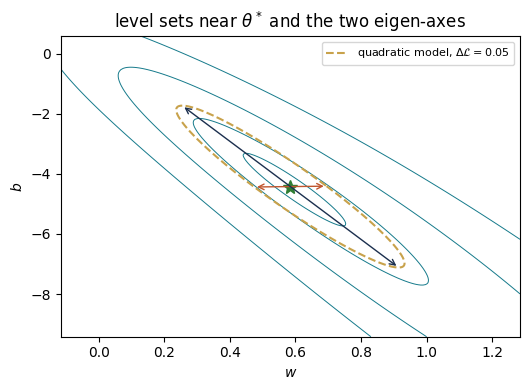

In [10]:
# Check cell for exercise 2. Do not modify.
lam_flat, lam_steep, q_flat, q_steep = eig_axes(H_star)
kappa_star = lam_steep / lam_flat
print(f"lambda_steep = {lam_steep:.4f} along q_steep = {np.round(q_steep, 4)}")
print(f"lambda_flat  = {lam_flat:.5f} along q_flat  = {np.round(q_flat, 4)}")
print(f"kappa(theta*) = {kappa_star:.1f}")
assert np.isclose(lam_steep, 8.0947, atol=1e-3) and np.isclose(lam_flat, 0.013551, atol=1e-5), "eigenvalues"
assert np.allclose(q_steep, [0.9926, 0.1215], atol=1e-3) and np.allclose(q_flat, [0.1215, -0.9926], atol=1e-3), \
    "eigenvectors (check the sign convention)"
assert abs(q_flat @ q_steep) < 1e-10, "the eigenvectors must be orthogonal"
assert np.allclose(H_star @ q_steep, lam_steep * q_steep, atol=1e-8), "H q must equal lambda q"
assert np.isclose(kappa_star, 597.36, atol=0.05), "kappa at theta* should be 597.4"
ax_steep, ax_flat = semi_axes(lam_flat, lam_steep, 0.05)
assert np.isclose(ax_steep, 0.1111, atol=1e-3) and np.isclose(ax_flat, 2.7165, atol=1e-3), "semi-axes"
assert np.isclose(ax_flat / ax_steep, np.sqrt(kappa_star)), "the axis ratio is sqrt(kappa)"
lf0, ls0, _, _ = eig_axes(hessian(0.0, 0.0))
print(f"kappa(0, 0) = {ls0 / lf0:.1f}")
assert np.isclose(ls0 / lf0, 253.38, atol=0.05), "kappa at the origin should be 253.4"
print("Exercise 2: all checks passed")

# The level sets of the true loss near theta*, the two eigen-axes, and the
# ellipse of the quadratic model at the same height as the second level set.
W, B = np.meshgrid(np.linspace(theta_star[0] - 0.7, theta_star[0] + 0.7, 200),
                   np.linspace(theta_star[1] - 5.0, theta_star[1] + 5.0, 200))
Z = y * (W[..., None] * x + B[..., None])
L = np.mean(np.logaddexp(0, -Z), axis=-1)
fig, ax = plt.subplots(figsize=(5.4, 4))
ax.contour(W, B, L, levels=L_star + np.array([0.01, 0.05, 0.2, 0.5]), colors=TEAL, linewidths=0.7)
t = np.linspace(0, 2 * np.pi, 200)
ellipse = theta_star[:, None] + ax_steep * np.cos(t) * q_steep[:, None] + ax_flat * np.sin(t) * q_flat[:, None]
ax.plot(ellipse[0], ellipse[1], color=GOLD, ls="--", label=r"quadratic model, $\Delta\mathcal{L} = 0.05$")
for q, r, c in [(q_steep, ax_steep, RUST), (q_flat, ax_flat, NAVY)]:
    ax.annotate("", xy=theta_star + r * q, xytext=theta_star - r * q,
                arrowprops=dict(arrowstyle="<->", color=c))
ax.plot(*theta_star, marker="*", color=GREEN, markersize=10)
ax.set_xlabel("$w$"); ax.set_ylabel("$b$"); ax.legend(fontsize=8, loc="upper right")
ax.set_title(r"level sets near $\theta^*$ and the two eigen-axes")
plt.tight_layout(); plt.show()

### Exercise 3: gradient descent in the eigenbasis

Implement `gd(theta0, lr, steps, xs=x)` as in lab 1, returning the iterates
and the losses, and `mode_coefficients(thetas, theta_star, q_flat,
q_steep)`, which projects every error $\mathbf{e}_t = \theta_t - \theta^*$
on the two axes: $a_i(t) = \mathbf{q}_i^\top \mathbf{e}_t$. Run 400 steps
from the origin with $\eta = 0.13$.

On the bowl of the chapter each coefficient would obey
$a_i(t+1) = (1 - \eta\lambda_i)\, a_i(t)$ exactly. Here the factor depends
on where the iterate stands. With $\eta = 0.13$, the steep factor
$1 - \eta\lambda_{\text{steep}}$ is $-0.786$ at the origin and $-0.052$ at
$\theta^*$; the flat factor $1 - \eta\lambda_{\text{flat}}$ is $0.9930$ at
the origin and $0.9982$ at $\theta^*$. Reference values: the loss sequence
starts $0.6931, 0.6848, 0.6781, \ldots$, reaches $0.6171$ at step 25 and
$0.4316$ at step 400, against $\mathcal{L}^* = 0.4174$. The steep
coefficient starts at $-0.0428$, alternates in sign at every step, and is
below $10\%$ of its start by step 8. The flat coefficient retains $90\%$ of
its start after 25 steps and $29\%$ after 400. Reaching
$\mathcal{L}^* + 10^{-3}$ takes 1008 steps.

In [12]:
def gd(theta0, lr, steps, xs=x):
    """Run gradient descent. Returns (thetas, losses):
    thetas: array of shape (steps + 1, 2), losses: array of shape (steps + 1,)."""
    thetas = np.empty((steps + 1, 2), dtype=float)
    losses = np.empty(steps + 1, dtype=float)

    thetas[0] = np.asarray(theta0, dtype=float)
    losses[0] = loss(*thetas[0], xs=xs)

    for t in range(steps):
        thetas[t + 1] = thetas[t] - lr * grad(*thetas[t], xs=xs)
        losses[t + 1] = loss(*thetas[t + 1], xs=xs)

    return thetas, losses

def mode_coefficients(thetas, theta_star, q_flat, q_steep):
    """Project the errors theta_t - theta_star on the two eigen-axes.
    Returns (a_flat, a_steep), each of shape (len(thetas),)."""
    errors = thetas - theta_star

    a_flat = errors @ q_flat
    a_steep = errors @ q_steep

    return a_flat, a_steep


flat-mode ratios at t = 0, 25, 100, 399: [0.99552 0.99583 0.99655 0.99765]
predicted from H(0, 0): 0.99295;  predicted from H(theta*): 0.99824
Exercise 3: all checks passed


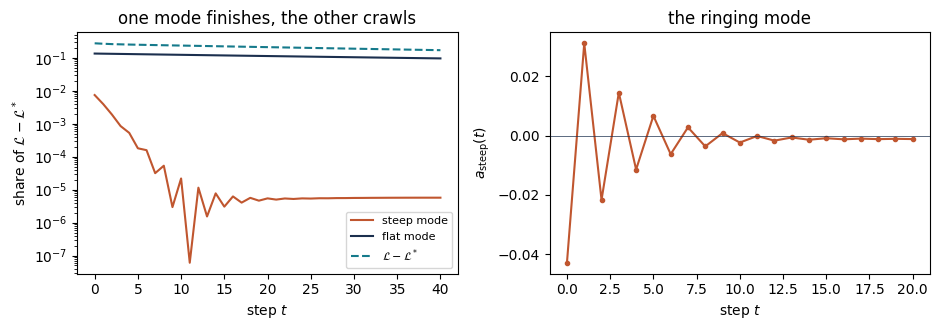

In [13]:
# Check cell for exercise 3. Do not modify.
ETA = 0.13
thetas, losses = gd((0.0, 0.0), lr=ETA, steps=400)
assert thetas.shape == (401, 2) and losses.shape == (401,), "wrong shapes"
assert np.allclose(losses[:3], [0.693147, 0.684835, 0.678145], atol=1e-5), \
    "the loss sequence should start 0.6931, 0.6848, 0.6781"
assert np.isclose(losses[25], 0.617107, atol=1e-5), "loss at t = 25 should be 0.6171"
assert np.isclose(losses[400], 0.431578, atol=1e-5), "loss at t = 400 should be 0.4316"
assert np.all(np.diff(losses) <= 1e-12), "at eta = 0.13 the loss never increases"

a_flat, a_steep = mode_coefficients(thetas, theta_star, q_flat, q_steep)
assert a_flat.shape == (401,) and a_steep.shape == (401,), "wrong shapes"
assert np.isclose(a_steep[0], -0.042836, atol=1e-5) and np.isclose(a_flat[0], -4.45988, atol=1e-4), \
    "the coefficients at t = 0 should be -0.0428 (steep) and -4.460 (flat)"
assert np.all(np.sign(a_steep[1:9]) == -np.sign(a_steep[:8])), "the steep coefficient must alternate in sign"
assert abs(a_steep[8] / a_steep[0]) < 0.10, "the steep coefficient should be below 10% of its start by step 8"
assert 0.85 < a_flat[25] / a_flat[0] < 0.95, "the flat coefficient should retain about 90% after 25 steps"
ratios_flat = a_flat[1:] / a_flat[:-1]
lo, hi = 1 - ETA * lf0, 1 - ETA * lam_flat
print(f"flat-mode ratios at t = 0, 25, 100, 399: {np.round(ratios_flat[[0, 25, 100, 399]], 5)}")
print(f"predicted from H(0, 0): {lo:.5f};  predicted from H(theta*): {hi:.5f}")
assert np.all((ratios_flat > lo) & (ratios_flat < hi)), \
    "every measured flat ratio should lie between the two predictions"
print("Exercise 3: all checks passed")

# Left: the loss carried by each mode, 0.5 * lambda_i * a_i(t)^2, over the
# first 40 steps. Far from theta* the two shares do not add up to the total,
# and the steep share bottoms out near 1e-5 instead of vanishing: the axes of
# H(theta*) are not exactly the axes of the Hessian along the path. Both are
# signs that the quadratic model is local. Right: the steep coefficient itself.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.4))
T = 40
ax1.semilogy(0.5 * lam_steep * a_steep[:T + 1] ** 2, color=RUST, label="steep mode")
ax1.semilogy(0.5 * lam_flat * a_flat[:T + 1] ** 2, color=NAVY, label="flat mode")
ax1.semilogy(losses[:T + 1] - L_star, color=TEAL, ls="--", label=r"$\mathcal{L} - \mathcal{L}^*$")
ax1.set_xlabel("step $t$"); ax1.set_ylabel(r"share of $\mathcal{L} - \mathcal{L}^*$"); ax1.legend(fontsize=8)
ax1.set_title("one mode finishes, the other crawls")
ax2.plot(a_steep[:21], color=RUST, marker=".")
ax2.axhline(0, color=NAVY, lw=0.5)
ax2.set_xlabel("step $t$"); ax2.set_ylabel(r"$a_{\mathrm{steep}}(t)$"); ax2.set_title("the ringing mode")
plt.tight_layout(); plt.show()

**Written answer 1.** The measured ratios $a_{\text{flat}}(t+1) / a_{\text{flat}}(t)$
lie between $0.9930$ and $0.9982$, the values predicted from $H(0, 0)$ and
from $H(\theta^*)$, and drift from the first toward the second as the run
proceeds. Explain why, and state which of the two Hessians decides the
largest step size a run from the origin can survive. Exercise 4 tests your
answer.

*Your answer:* The logistic-regression Hessian changes as gradient descent moves. At the origin, the loss has higher curvature, giving a flat-mode factor of about $0.9930$. As the iterates approach $H(\theta^*)$, the curvature in that direction decreases, so the measured ratio moves toward the local factor $0.9982$. The fixed eigenvectors of $H(\theta^*)$ also only approximate the directions along the earlier part of the path. For a run starting at the origin, $H(0,0)$ sets the more restrictive safe learning-rate bound: $2/\lambda_{\max}(0,0)\approx0.1456$, compared with about $0.247$ near $H(\theta^*)$. A step chosen using only the Hessian at $H(\theta^*)$ can therefore increase the loss early in the run.

### Exercise 4: the stability threshold and the best fixed step

Near $\theta^*$ the quadratic model is accurate and the predictions of the
chapter can be tested directly. Implement `steep_magnitudes(theta0, lr,
steps)`, which runs `gd` from `theta0`, projects with `mode_coefficients`,
and returns $|a_{\text{steep}}(t)|$; and `best_step(lam_flat, lam_steep)`,
which returns $\eta^* = 2/(\lambda_{\max} + \lambda_{\min})$ and the common
factor $(\kappa - 1)/(\kappa + 1)$.

The check cell starts at $\theta_{\text{near}} = \theta^* + 0.02\,
\mathbf{q}_{\text{steep}} + 0.1\, \mathbf{q}_{\text{flat}}$ and runs 60
steps at $\eta = f \cdot 2/\lambda_{\max}(\theta^*)$ for $f = 0.9, 1.0,
1.1$. Below the threshold the steep coefficient must decay, to under $5\%$
of its start by step 20; above it, it must grow past its start. It then runs
200 steps at $\eta^*$ and measures the flat ratio at step 100. Reference
values: $\eta^* = 0.2467$, factor $0.99666$, that is $299$ steps per factor
$e$; measured flat ratio $0.9967$.

Finally the origin. The step size $\eta = 0.95 \cdot 2/\lambda_{\max}(\theta^*)
= 0.2347$ is below the threshold at $\theta^*$ and above the threshold
$0.1456$ at the origin. The check cell runs 200 steps from $(0, 0)$ at this
$\eta$ and at $\eta = 0.13$, and tests which of the two runs decreases the
loss at every step.

In [14]:
def steep_magnitudes(theta0, lr, steps):
    """|a_steep(t)| along a GD run from theta0, using theta_star, q_flat, q_steep."""
    thetas, _ = gd(theta0, lr=lr, steps=steps)
    _, a_steep = mode_coefficients(
        thetas, theta_star, q_flat, q_steep
    )
    return np.abs(a_steep)

def best_step(lam_flat, lam_steep):
    """The best fixed step size and its contraction factor: (eta_star, factor)."""
    eta_star = 2 / (lam_steep + lam_flat)

    kappa = lam_steep / lam_flat
    factor = (kappa - 1) / (kappa + 1)

    return eta_star, factor


eta = 0.9 x 2/lambda_max:  |a_steep| at t = 0, 5, 20, 60 = [0.02    0.00528 0.00012 0.     ]
eta = 1.0 x 2/lambda_max:  |a_steep| at t = 0, 5, 20, 60 = [0.02    0.01615 0.01111 0.00412]
eta = 1.1 x 2/lambda_max:  |a_steep| at t = 0, 5, 20, 60 = [0.02    0.03906 0.15905 0.15151]
eta* = 0.2467, factor (kappa - 1)/(kappa + 1) = 0.99666, steps per factor e: 299
measured flat ratio at t = 100: 0.99671
from the origin at eta = 0.2347: losses t = 0..5 = [0.693 0.727 0.83  1.1   0.931 1.225]
Exercise 4: all checks passed


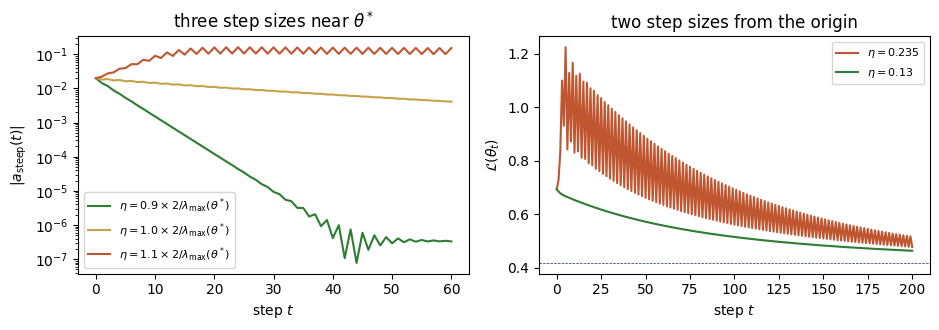

In [15]:
# Check cell for exercise 4. Do not modify.
theta_near = theta_star + 0.02 * q_steep + 0.1 * q_flat
eta_edge = 2 / lam_steep
runs = {}
for f in [0.9, 1.0, 1.1]:
    runs[f] = steep_magnitudes(theta_near, lr=f * eta_edge, steps=60)
    print(f"eta = {f:.1f} x 2/lambda_max:  |a_steep| at t = 0, 5, 20, 60 = {np.round(runs[f][[0, 5, 20, 60]], 5)}")
assert runs[0.9].shape == (61,), "wrong shape"
assert runs[0.9][20] < 0.05 * runs[0.9][0], "below the threshold the steep coefficient must decay"
assert runs[1.1][20] > runs[1.1][0], "above the threshold the steep coefficient must grow"

eta_star, factor = best_step(lam_flat, lam_steep)
print(f"eta* = {eta_star:.4f}, factor (kappa - 1)/(kappa + 1) = {factor:.5f}, steps per factor e: {-1 / np.log(factor):.0f}")
assert np.isclose(eta_star, 0.246661, atol=1e-5) and np.isclose(factor, 0.996658, atol=1e-5), "eta* and its factor"
thetas_best, _ = gd(theta_near, lr=eta_star, steps=200)
a_flat_best, _ = mode_coefficients(thetas_best, theta_star, q_flat, q_steep)
ratio_100 = a_flat_best[101] / a_flat_best[100]
print(f"measured flat ratio at t = 100: {ratio_100:.5f}")
assert np.isclose(ratio_100, factor, atol=1e-3), "the flat mode should contract by (kappa - 1)/(kappa + 1) per step"

eta_bad = 0.95 * eta_edge
_, losses_bad = gd((0.0, 0.0), lr=eta_bad, steps=200)
_, losses_ok = gd((0.0, 0.0), lr=0.13, steps=200)
print(f"from the origin at eta = {eta_bad:.4f}: losses t = 0..5 = {np.round(losses_bad[:6], 3)}")
assert np.any(np.diff(losses_bad) > 0), "eta = 0.95 x 2/lambda_max(theta*) must raise the loss at some step from the origin"
assert np.all(np.diff(losses_ok) <= 1e-12), "eta = 0.13 must decrease the loss at every step from the origin"
print("Exercise 4: all checks passed")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.5, 3.4))
for f, c in zip([0.9, 1.0, 1.1], [GREEN, GOLD, RUST]):
    ax1.semilogy(runs[f], color=c, label=rf"$\eta = {f} \times 2/\lambda_{{\max}}(\theta^*)$")
ax1.set_xlabel("step $t$"); ax1.set_ylabel(r"$|a_{\mathrm{steep}}(t)|$"); ax1.legend(fontsize=8)
ax1.set_title(r"three step sizes near $\theta^*$")
ax2.plot(losses_bad, color=RUST, label=rf"$\eta = {eta_bad:.3f}$")
ax2.plot(losses_ok, color=GREEN, label=r"$\eta = 0.13$")
ax2.axhline(L_star, color=NAVY, lw=0.5, ls="--")
ax2.set_xlabel("step $t$"); ax2.set_ylabel(r"$\mathcal{L}(\theta_t)$"); ax2.legend(fontsize=8)
ax2.set_title("two step sizes from the origin")
plt.tight_layout(); plt.show()

## Part C: the three remedies

### Exercise 5: Newton's method

Newton's step replaces the scalar $\eta$ by the matrix $H^{-1}$:

$$\theta_{t+1} = \theta_t - H(\theta_t)^{-1}\, \nabla \mathcal{L}(\theta_t) .$$

On the bowl of the chapter one step lands on $\theta^*$. Here $H$ changes
along the way, so each step lands on the minimizer of the current quadratic
model and the next step corrects it. Implement `newton_step(theta, xs=x)`,
which solves $H \mathbf{d} = \nabla \mathcal{L}$ with `np.linalg.solve` and
returns $\theta - \mathbf{d}$ (never form the inverse), and `newton(theta0,
steps, xs=x)`, which returns the iterates. Run 8 steps from the origin.

Reference values: the loss sequence is $0.6931, 0.4411, 0.4189, 0.41743,
0.417423, \ldots$; the errors $\lVert \theta_t - \theta^* \rVert$ are
$4.46,\ 1.65,\ 0.453,\ 0.0403,\ 3.3 \times 10^{-4},\ 2 \times 10^{-8}$, and
from the first step on each is below the square of the previous one, the
quadratic convergence of N&W section 3.3. Newton's method reaches
$\mathcal{L}^* + 10^{-3}$ at step 3; gradient descent at $\eta = 0.13$
reaches it at step 1008.

In [16]:
def newton_step(theta, xs=x):
    """One Newton step from theta: solve H d = grad and return theta - d."""
    w, b = theta

    g = grad(w, b, xs=xs)
    H = hessian(w, b, xs=xs)

    direction = np.linalg.solve(H, g)
    return np.asarray(theta, dtype=float) - direction

def newton(theta0, steps, xs=x):
    """Run Newton's method. Returns the iterates, an array of shape (steps + 1, 2)."""
    thetas = np.empty((steps + 1, 2), dtype=float)
    thetas[0] = np.asarray(theta0, dtype=float)

    for t in range(steps):
        thetas[t + 1] = newton_step(thetas[t], xs=xs)

    return thetas


Newton losses: [0.693147 0.44106  0.418909 0.417434 0.417423 0.417423]
Newton errors: [4.46008605e+00 1.64678786e+00 4.53063048e-01 4.02578296e-02
 3.33449417e-04 2.29796339e-08 0.00000000e+00]
steps to reach L* + 0.001: Newton 3, gradient descent 1008
Exercise 5: all checks passed


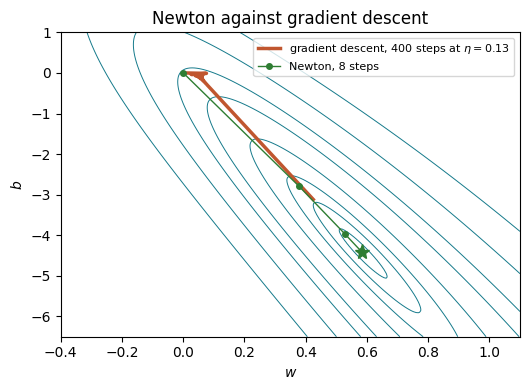

In [17]:
# Check cell for exercise 5. Do not modify.
newton_thetas = newton((0.0, 0.0), steps=8)
assert newton_thetas.shape == (9, 2), "wrong shape"
newton_losses = np.array([loss(*th) for th in newton_thetas])
theta_exact = newton_thetas[-1]                     # the converged point, to full precision
newton_errors = np.linalg.norm(newton_thetas - theta_exact, axis=1)
print("Newton losses:", np.round(newton_losses[:6], 6))
print("Newton errors:", newton_errors[:7])
assert np.allclose(newton_losses[:4], [0.693147, 0.441060, 0.418909, 0.417434], atol=1e-5), \
    "the loss sequence should be 0.6931, 0.4411, 0.4189, 0.4174"
assert np.allclose(theta_exact, theta_star, atol=1e-6), "eight Newton steps must land on theta*"
assert newton_errors[6] < 1e-10, "the error after six steps should be at machine precision"
assert np.all(newton_errors[1:6] < newton_errors[:5] ** 2), \
    "each error should be below the square of the previous one"
steps_newton = int(np.argmax(newton_losses - L_star < 1e-3))
_, losses_long = gd((0.0, 0.0), lr=0.13, steps=1200)
steps_gd = int(np.argmax(losses_long - L_star < 1e-3))
print(f"steps to reach L* + 0.001: Newton {steps_newton}, gradient descent {steps_gd}")
assert steps_newton == 3 and steps_gd == 1008, "steps to L* + 0.001"
print("Exercise 5: all checks passed")

# Both methods from the origin, over the level sets of the loss.
W, B = np.meshgrid(np.linspace(-0.4, 1.1, 200), np.linspace(-6.5, 1.0, 200))
Z = y * (W[..., None] * x + B[..., None])
L = np.mean(np.logaddexp(0, -Z), axis=-1)
fig, ax = plt.subplots(figsize=(5.4, 4))
ax.contour(W, B, L, levels=[0.42, 0.43, 0.45, 0.5, 0.6, 0.7, 0.9, 1.2], colors=TEAL, linewidths=0.7)
ax.plot(thetas[:, 0], thetas[:, 1], color=RUST, lw=2.5, label=r"gradient descent, 400 steps at $\eta = 0.13$")
ax.plot(newton_thetas[:, 0], newton_thetas[:, 1], color=GREEN, marker="o", markersize=4, lw=1, label="Newton, 8 steps")
ax.plot(*theta_star, marker="*", color=GREEN, markersize=11)
ax.set_xlabel("$w$"); ax.set_ylabel("$b$"); ax.legend(fontsize=8)
ax.set_title("Newton against gradient descent")
plt.tight_layout(); plt.show()

**Written answer 2.** On the bowl of the chapter one Newton step reaches
$\theta^*$ from anywhere. Here the first step lands at loss $0.4411$, not
$0.4174$, and four steps are needed. Say what one Newton step minimizes
exactly, and why that object coincides with $\mathcal{L}$ only on a
quadratic. Then name the three obstacles the chapter raises against
Newton's method at network scale, and state which one cannot occur on this
problem, and why.

*Your answer:* A Newton step exactly minimizes the quadratic model built from the current loss, gradient, and Hessian. On a quadratic loss, that model is the true loss everywhere, so one step reaches the minimum. Logistic loss has a Hessian that changes with the parameters, so its quadratic model is only local and further steps are needed. At network scale, Newton’s method faces the memory cost of storing the Hessian, the computation needed to solve the linear system, and unreliable directions when the Hessian has negative eigenvalues. Negative curvature cannot occur in this lab because this logistic-regression loss is convex and its Hessian is positive definite for the given data.

### Exercise 6: diagonal preconditioning

A preconditioner rescales the gradient before the step:
$\theta_{t+1} = \theta_t - \eta\, P\, \nabla \mathcal{L}(\theta_t)$. The
cheap choice keeps only the diagonal of the Hessian, $P = D^{-1}$ with
$D = \operatorname{diag}\big(H(0, 0)\big) = \operatorname{diag}(13.5417,\ 0.25)$,
two numbers available before training: $w$ then steps by $\eta / 13.54$ and
$b$ by $\eta / 0.25$. In the rescaled coordinates $\mathbf{u} = D^{1/2}\theta$
this is plain gradient descent on a loss whose Hessian is
$D^{-1/2} H D^{-1/2}$, so the threshold and the condition number are read off
that matrix.

Implement `pgd(theta0, lr, steps, d, xs=x)`, gradient descent with the
gradient divided entrywise by the vector `d`, and `precond_kappa(H, d)`, the
condition number of $D^{-1/2} H D^{-1/2}$. Reference values:
$D^{-1/2} H(0, 0)\, D^{-1/2} = \begin{pmatrix} 1 & 0.883 \\ 0.883 & 1 \end{pmatrix}$
with $\kappa = 16.12$, down from $253.4$; the same at $\theta^*$ gives
$\kappa = 36.7$, down from $597.4$; the threshold at the origin becomes
$2 / 1.883 = 1.062$. The check cell runs 400 steps from the origin at
$\eta = 0.9 \times 1.062 = 0.956$: the loss is $0.4310$ at step 25 and
$0.41752$ at step 100, and $\mathcal{L}^* + 10^{-3}$ is reached at step 62
instead of 1008. The off-diagonal survives: with $\rho = 0.883$ the
correlation of the two columns of $D^{-1/2} H D^{-1/2}$, the residual
condition number is $(1 + \rho)/(1 - \rho) = 16.12$, because a diagonal
matrix cannot remove the coupling between $w$ and $b$.

In [18]:
def pgd(theta0, lr, steps, d, xs=x):
    """Preconditioned gradient descent with P = diag(1 / d). Returns (thetas, losses)."""
    thetas = np.empty((steps + 1, 2), dtype=float)
    losses = np.empty(steps + 1, dtype=float)

    thetas[0] = np.asarray(theta0, dtype=float)
    losses[0] = loss(*thetas[0], xs=xs)

    for t in range(steps):
        g = grad(*thetas[t], xs=xs)
        thetas[t + 1] = thetas[t] - lr * (g / d)
        losses[t + 1] = loss(*thetas[t + 1], xs=xs)

    return thetas, losses


def precond_kappa(H, d):
    """Condition number of D^{-1/2} H D^{-1/2} with D = diag(d)."""
    inv_sqrt_D = np.diag(1 / np.sqrt(d))
    H_rescaled = inv_sqrt_D @ H @ inv_sqrt_D

    eigenvalues = np.linalg.eigvalsh(H_rescaled)
    return eigenvalues[-1] / eigenvalues[0]


In [19]:
# Check cell for exercise 6. Do not modify.
d = np.diag(hessian(0.0, 0.0))
print("D = diag", np.round(d, 4))
kappa_p0, kappa_ps = precond_kappa(hessian(0.0, 0.0), d), precond_kappa(H_star, d)
print(f"kappa at (0, 0): {ls0 / lf0:.1f} -> {kappa_p0:.2f};   kappa at theta*: {kappa_star:.1f} -> {kappa_ps:.2f}")
assert np.isclose(kappa_p0, 16.1198, atol=1e-3) and np.isclose(kappa_ps, 36.7234, atol=1e-3), "preconditioned kappa"
rho = 1.625 / np.sqrt(13.541667 * 0.25)
assert np.isclose(kappa_p0, (1 + rho) / (1 - rho), atol=1e-4), "with a diagonal D the residual kappa is (1 + rho)/(1 - rho)"
Hp0 = np.diag(1 / np.sqrt(d)) @ hessian(0.0, 0.0) @ np.diag(1 / np.sqrt(d))
eta_p = 0.9 * 2 / np.linalg.eigvalsh(Hp0)[-1]
thetas_p, losses_p = pgd((0.0, 0.0), lr=eta_p, steps=400, d=d)
assert thetas_p.shape == (401, 2) and losses_p.shape == (401,), "wrong shapes"
print(f"preconditioned, eta = {eta_p:.3f}: L(25) = {losses_p[25]:.4f}, L(100) = {losses_p[100]:.5f};"
      f"   plain, eta = 0.13: L(25) = {losses[25]:.4f}, L(100) = {losses[100]:.5f}")
assert np.isclose(losses_p[25], 0.431024, atol=1e-5) and np.isclose(losses_p[100], 0.417518, atol=1e-5), \
    "preconditioned losses at t = 25 and t = 100"
assert np.all(np.diff(losses_p) <= 1e-12), "the preconditioned run should decrease at every step"
steps_p = int(np.argmax(losses_p - L_star < 1e-3))
print(f"steps to reach L* + 0.001: preconditioned {steps_p}, plain 1008")
assert steps_p == 62, "steps to L* + 0.001"
print("Exercise 6: all checks passed")

D = diag [13.5417  0.25  ]
kappa at (0, 0): 253.4 -> 16.12;   kappa at theta*: 597.4 -> 36.72
preconditioned, eta = 0.956: L(25) = 0.4310, L(100) = 0.41752;   plain, eta = 0.13: L(25) = 0.6171, L(100) = 0.51461
steps to reach L* + 0.001: preconditioned 62, plain 1008
Exercise 6: all checks passed


### Exercise 7: scaling the data

The Hessian is built from the outer products $\tilde{x}_i \tilde{x}_i^\top$,
so the units of the feature enter it squared, exactly as in
$H = \frac{2}{N} X^\top X$ for least squares. Three rescaled versions of the
same dataset:

- centered: $\tilde{x} = x - \bar{x}$ with $\bar{x} = 6.5$;
- standardized: $\tilde{x} = (x - \bar{x}) / s$ with $s = 3.452$ (use
  `np.std`, the population standard deviation);
- the years trap: the age re-entered as the installation year,
  $x_{\text{year}} = 2024 - x$.

Each version has its own minimizer, but the same minimal loss $0.4174$ and
the same predictions: the model is the same function in different
coordinates. Build the three feature vectors and implement `analyze(xs)`,
which returns `(theta_star, kappa_star, kappa_origin, threshold_origin)`:
the minimizer (12 Newton steps from the origin), $\kappa$ at the minimizer,
$\kappa$ at the origin, and the threshold $2/\lambda_{\max}$ at the origin.

Reference values. Centered: $H(0, 0) = \operatorname{diag}(2.979,\ 0.25)$,
$\kappa = 11.92$ at the origin and $7.94$ at $\theta^*$, threshold $0.671$.
Standardized: $H(0, 0) = 0.25\, I$, $\kappa = 1$ at the origin and $2.37$ at
$\theta^*$, threshold $8$. Years: $\kappa = 1.4 \times 10^{12}$ at the origin,
threshold $2 \times 10^{-6}$. The check cell also verifies that Newton's
loss sequence is identical on all four versions (the method is invariant
under affine changes of coordinates), and runs gradient descent from the
origin on the centered data at $\eta = 0.6$ and on the standardized data at
$\eta = 7.2$: they reach $\mathcal{L}^* + 10^{-3}$ at steps 20 and 2. The
centered $\kappa$ is not $1$ and the standardized $\kappa$ at $\theta^*$ is
not $1$ either: the weights $\sigma(z_i)(1 - \sigma(z_i))$ are unequal at
the minimizer, so rescaling the columns of $X$ does not exactly rescale the
columns of $H$. Centering still removes most of the tilt, and standardizing
still removes most of the scale gap.

In [22]:
x_centered = x - np.mean(x)
x_standardized = (x - np.mean(x)) / np.std(x)
x_years = 2024 - x

def analyze(xs):
    """Condition numbers of the problem with feature vector xs.
    Returns (theta_star, kappa_star, kappa_origin, threshold_origin): the minimizer
    (12 Newton steps from the origin), kappa at the minimizer, kappa at the origin,
    and the threshold 2 / lambda_max at the origin."""
    theta_best = newton((0.0, 0.0), steps=12, xs=xs)[-1]

    H_best = hessian(*theta_best, xs=xs)
    lam_flat_best, lam_steep_best, _, _ = eig_axes(H_best)
    kappa_best = lam_steep_best / lam_flat_best

    H_origin = hessian(0.0, 0.0, xs=xs)
    lam_flat_origin, lam_steep_origin, _, _ = eig_axes(H_origin)
    kappa_origin = lam_steep_origin / lam_flat_origin
    threshold_origin = 2 / lam_steep_origin

    return theta_best, kappa_best, kappa_origin, threshold_origin


raw           theta* = (  0.5845,    -4.4216)   L* = 0.417423   kappa(theta*) =      597.4   kappa(0, 0) =      253.4   2/lambda_max(0, 0) = 0.1456
centered      theta* = (  0.5845,    -0.6224)   L* = 0.417423   kappa(theta*) =      7.944   kappa(0, 0) =      11.92   2/lambda_max(0, 0) = 0.6713
standardized  theta* = (  2.0177,    -0.6224)   L* = 0.417423   kappa(theta*) =      2.365   kappa(0, 0) =          1   2/lambda_max(0, 0) = 8
years         theta* = ( -0.5845,  1178.5929)   L* = 0.417423   kappa(theta*) =  2.663e+12   kappa(0, 0) =   1.39e+12   2/lambda_max(0, 0) = 1.965e-06
Newton's loss sequence is identical on all four versions of the data.
centered, eta = 0.6: L(25) = 0.417877;   standardized, eta = 7.2: L(25) = 0.417423;   L* = 0.417423
Exercise 7: all checks passed


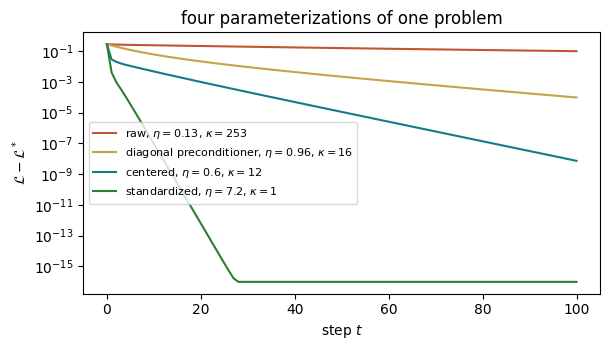

In [23]:
# Check cell for exercise 7. Do not modify.
assert np.isclose(x_centered.mean(), 0) and np.isclose(x_standardized.std(), 1) and np.isclose(x_years[0], 2023), \
    "the three feature vectors"
table = {}
for name, xs in [("raw", x), ("centered", x_centered), ("standardized", x_standardized), ("years", x_years)]:
    ts, ks, k0, thr = analyze(xs)
    table[name] = (ts, ks, k0, thr)
    print(f"{name:13s} theta* = ({ts[0]:8.4f}, {ts[1]:10.4f})   L* = {loss(*ts, xs=xs):.6f}"
          f"   kappa(theta*) = {ks:10.4g}   kappa(0, 0) = {k0:10.4g}   2/lambda_max(0, 0) = {thr:.4g}")
    assert np.isclose(loss(*ts, xs=xs), L_star, atol=1e-8), "every version has the same minimal loss"
assert np.isclose(table["raw"][1], 597.36, atol=0.05) and np.isclose(table["raw"][2], 253.38, atol=0.05), "raw kappa"
assert np.isclose(table["centered"][1], 7.9439, atol=1e-3) and np.isclose(table["centered"][2], 11.9167, atol=1e-3), \
    "centered kappa"
assert np.isclose(table["centered"][3], 0.67133, atol=1e-4), "centered threshold"
assert np.isclose(table["standardized"][1], 2.3651, atol=1e-3) and np.isclose(table["standardized"][2], 1.0, atol=1e-8), \
    "standardized kappa"
assert np.isclose(table["standardized"][3], 8.0, atol=1e-8), "standardized threshold"
assert table["years"][2] > 1e11, "the years feature should give kappa above 1e11 at the origin"
assert np.isclose(table["years"][0][0], -table["raw"][0][0], atol=1e-6), "x -> 2024 - x flips the sign of w*"
# Affine invariance: Newton's iterates are the same model at every step, whatever the units.
for name, xs in [("centered", x_centered), ("standardized", x_standardized), ("years", x_years)]:
    seq = [loss(*th, xs=xs) for th in newton((0.0, 0.0), steps=6, xs=xs)]
    assert np.allclose(seq, newton_losses[:7], atol=1e-9), f"Newton's loss sequence on the {name} data should equal the raw one"
print("Newton's loss sequence is identical on all four versions of the data.")
_, losses_c = gd((0.0, 0.0), lr=0.6, steps=100, xs=x_centered)
_, losses_s = gd((0.0, 0.0), lr=7.2, steps=100, xs=x_standardized)
print(f"centered, eta = 0.6: L(25) = {losses_c[25]:.6f};   standardized, eta = 7.2: L(25) = {losses_s[25]:.6f};   L* = {L_star:.6f}")
assert np.isclose(losses_c[25], 0.417877, atol=1e-5) and np.isclose(losses_s[25], L_star, atol=1e-6), "losses at t = 25"
assert int(np.argmax(losses_c - L_star < 1e-3)) == 20 and int(np.argmax(losses_s - L_star < 1e-3)) == 2, "steps to L* + 0.001"
print("Exercise 7: all checks passed")

# One problem, four parameterizations, each run from the origin at 0.9 times
# its own threshold (kappa in the legend is the value at the origin).
fig, ax = plt.subplots(figsize=(6.2, 3.6))
for label, seq, c in [(r"raw, $\eta = 0.13$, $\kappa = 253$", losses[:101], RUST),
                      (rf"diagonal preconditioner, $\eta = {eta_p:.2f}$, $\kappa = 16$", losses_p[:101], GOLD),
                      (r"centered, $\eta = 0.6$, $\kappa = 12$", losses_c, TEAL),
                      (r"standardized, $\eta = 7.2$, $\kappa = 1$", losses_s, GREEN)]:
    ax.semilogy(np.maximum(seq - L_star, 1e-16), color=c, label=label)
ax.set_xlabel("step $t$"); ax.set_ylabel(r"$\mathcal{L} - \mathcal{L}^*$"); ax.legend(fontsize=8)
ax.set_title("four parameterizations of one problem")
plt.tight_layout(); plt.show()

### Exercise 8 (optional): the Hessian from autograd

PyTorch differentiates twice as easily as once. Write the loss as a function
of a single tensor `theta` of shape `(2,)`, obtain the Hessian at $\theta^*$
with `torch.func.hessian`, and compare it with your `hessian` from
exercise 1; then read off its eigenvalues with `torch.linalg.eigvalsh`. At
$d = 10^9$ the full matrix cannot be formed, but the same machinery returns
Hessian-vector products $H\mathbf{v}$ at the cost of one extra backward
pass, which is how $\lambda_{\max}$ of a network is estimated in practice.

In [ ]:
try:
    import torch

    xt, yt = torch.tensor(x), torch.tensor(y)

    def loss_torch(theta):
        # TODO: the loss of exercise 1 from the tensor theta = (w, b);
        # torch.nn.functional.softplus(-z) computes log(1 + exp(-z)).
        ...

    H_autograd = torch.func.hessian(loss_torch)(torch.tensor(theta_star))
    print("Hessian from autograd:\n", H_autograd.numpy())
    assert np.allclose(H_autograd.numpy(), H_star, atol=1e-8), "autograd and the formula disagree"
    print("eigenvalues:", torch.linalg.eigvalsh(H_autograd).numpy())
    print("Exercise 8: all checks passed")

except ImportError:
    print("PyTorch is not installed; this optional exercise is skipped.")